# 01 — Exploratory data analysis

Dataset: [Roboflow-100 Vehicles](https://universe.roboflow.com/roboflow-100/vehicles-q0x2v/dataset/2)
(v2, CC BY 4.0). Run `python scripts/download_data.py` first.

Questions this notebook answers:

1. How balanced are the 12 classes, and are any too rare to evaluate?
2. The class names follow two naming schemes (`big/mid/small truck` and `truck-s-/-m-/-l-/-xl-`).
   Are these separate source datasets or the same vehicles labelled two ways?
3. Do frames from the same video appear in several splits?
4. Is merging into **car / bus / truck** justified?

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tdb.data.classes import ClassConfig
from tdb.data.yolo import SPLITS, iter_split, source_video

ROOT = Path("..") / "data" / "vehicles"
cfg = ClassConfig.load()
NAMES = cfg.original
SCHEME_A = {"big bus", "big truck", "mid truck", "small bus", "small truck"}
SCHEME_B = {"bus-l-", "bus-s-", "truck-l-", "truck-m-", "truck-s-", "truck-xl-"}

rows, images = [], []
for split in SPLITS:
    for img, boxes in iter_split(ROOT, split):
        images.append(
            {
                "split": split,
                "image": img.name,
                "source": source_video(img.name),
                "n_boxes": len(boxes),
            }
        )
        for b in boxes:
            name = NAMES[b.cls]
            rows.append(
                {
                    "split": split,
                    "image": img.name,
                    "source": source_video(img.name),
                    "cls": name,
                    "merged": cfg.mapping[name],
                    "scheme": "A" if name in SCHEME_A else "B" if name in SCHEME_B else "-",
                    "cx": b.cx,
                    "cy": b.cy,
                    "w": b.w,
                    "h": b.h,
                }
            )
boxes = pd.DataFrame(rows)
boxes["area_pct"] = boxes.w * boxes.h * 100
imgs = pd.DataFrame(images)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(imgs)} images, {len(boxes)} boxes")
imgs.groupby("split").agg(
    images=("image", "size"), boxes=("n_boxes", "sum"), boxes_per_image=("n_boxes", "mean")
).round(1)

4058 images, 51577 boxes


,images,boxes,boxes_per_image
split,,,
test,458,6222,13.6
train,2634,31905,12.1
valid,966,13450,13.9


## 1. Class balance per split

In [2]:
counts = boxes.pivot_table(
    index="cls", columns="split", values="image", aggfunc="size", fill_value=0
)[list(SPLITS)].reindex(NAMES)
counts["total"] = counts.sum(axis=1)
counts.sort_values("total", ascending=False)

split,train,valid,test,total
cls,,,,
car,19083,8537,4021,31641
small truck,3294,1721,827,5842
truck-m-,2760,629,283,3672
big truck,1822,1162,648,3632
truck-l-,1701,433,144,2278
truck-s-,1111,221,31,1363
truck-xl-,641,148,32,821
big bus,433,273,110,816
mid truck,359,257,87,703


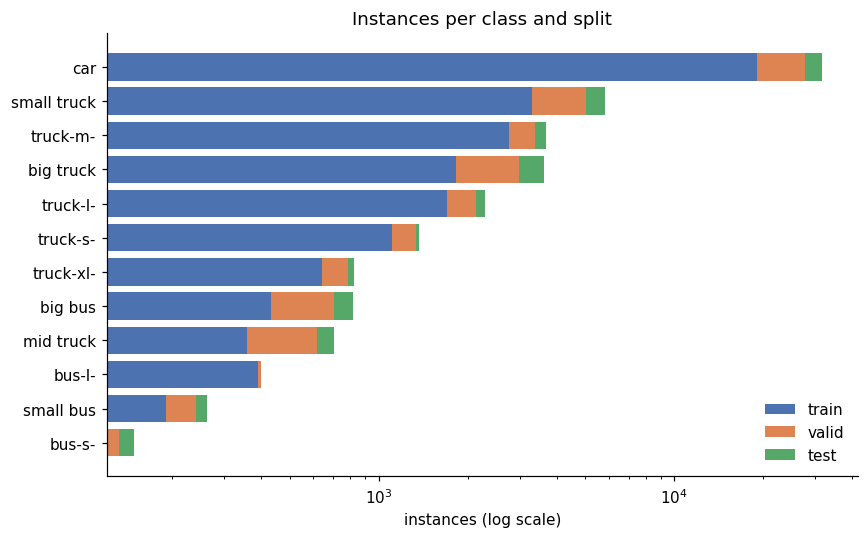

In [3]:
order = counts.sort_values("total").index
fig, ax = plt.subplots(figsize=(8, 5))
left = np.zeros(len(order))
for split, color in zip(SPLITS, ["#4C72B0", "#DD8452", "#55A868"], strict=True):
    vals = counts.loc[order, split].values
    ax.barh(order, vals, left=left, color=color, label=split)
    left += vals
ax.set_xscale("log")
ax.set_xlabel("instances (log scale)")
ax.set_title("Instances per class and split")
ax.legend(frameon=False)
plt.tight_layout()

**Findings**

- `car` is ~61% of all boxes; the rarest class (`bus-s-`) has 148 instances in total.
- `bus-l-` has **0 test instances and 8 validation instances**, and `bus-s-` has 16 test
  instances. Per-class AP for these classes is noise, which is why the original YOLOv5 run
  reported mAP@0.5 of 0.04 for `bus-l-`.

## 2. Two naming schemes: separate sources or the same vehicles?

In [4]:
per_image = boxes[boxes.scheme != "-"].groupby("image").scheme.agg(set)
both = per_image.apply(lambda s: s == {"A", "B"}).sum()
print(f"images with vehicles from BOTH schemes: {both} of {len(per_image)}")

src = boxes[boxes.scheme != "-"].pivot_table(
    index="source", columns="scheme", values="image", aggfunc="size", fill_value=0
)
src["share_B"] = (src.B / (src.A + src.B)).round(2)
src

images with vehicles from BOTH schemes: 1096 of 3734


scheme,A,B,share_B
source,,,
adit,9124,2104,0.19
aditganteng,387,1722,0.82
malam_04112021,26,618,0.96
pagi_16112021,1671,2904,0.63
siang_15112021_1,48,1332,0.97


Every source video uses both schemes, and 1,096 images contain both. So the two schemes are not
two datasets merged together: the same scenes were labelled inconsistently. Next, we check
whether the size words mean the same thing in both schemes.

,count,50%,90%
cls,,,
car,31641.0,0.34,1.84
small truck,5842.0,0.68,2.35
truck-s-,1363.0,0.53,2.37
mid truck,703.0,0.94,4.39
truck-m-,3672.0,0.88,4.00
big truck,3632.0,1.47,7.98
truck-l-,2278.0,1.13,6.22
truck-xl-,821.0,1.34,7.49
small bus,263.0,0.78,2.28


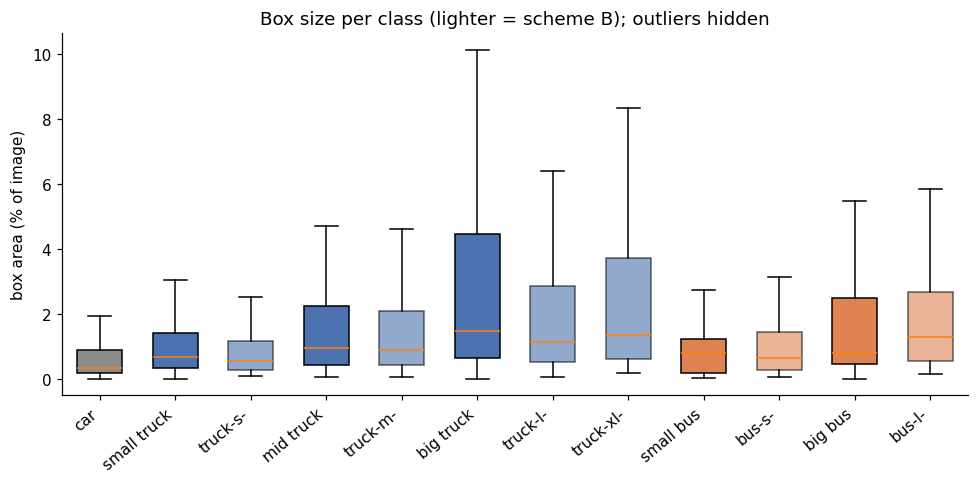

In [5]:
ladder = [
    "car",
    "small truck",
    "truck-s-",
    "mid truck",
    "truck-m-",
    "big truck",
    "truck-l-",
    "truck-xl-",
    "small bus",
    "bus-s-",
    "big bus",
    "bus-l-",
]
colors = {"car": "#8C8C8C", "truck": "#4C72B0", "bus": "#DD8452"}
fig, ax = plt.subplots(figsize=(9, 4.5))
data = [boxes.loc[boxes.cls == c, "area_pct"] for c in ladder]
bp = ax.boxplot(data, vert=True, showfliers=False, patch_artist=True, widths=0.6)
for patch, c in zip(bp["boxes"], ladder, strict=True):
    patch.set_facecolor(colors[cfg.mapping[c]])
    patch.set_alpha(0.6 if c in SCHEME_B else 1.0)
ax.set_xticks(range(1, len(ladder) + 1), ladder, rotation=40, ha="right")
ax.set_ylabel("box area (% of image)")
ax.set_title("Box size per class (lighter = scheme B); outliers hidden")
plt.tight_layout()

boxes.groupby("cls").area_pct.describe(percentiles=[0.5, 0.9])[["count", "50%", "90%"]].reindex(
    ladder
).round(2)

The two schemes are the same size scale under different names: `truck-s-` ≈ `small truck`,
`truck-m-` ≈ `mid truck`, `truck-l-`/`truck-xl-` ≈ `big truck`. The size classes also overlap
heavily with each other, and box size depends on distance to the camera as much as on the
vehicle. `small bus` and `big bus` even have the same median area.

The crops below show random examples of the truck size classes side by side.

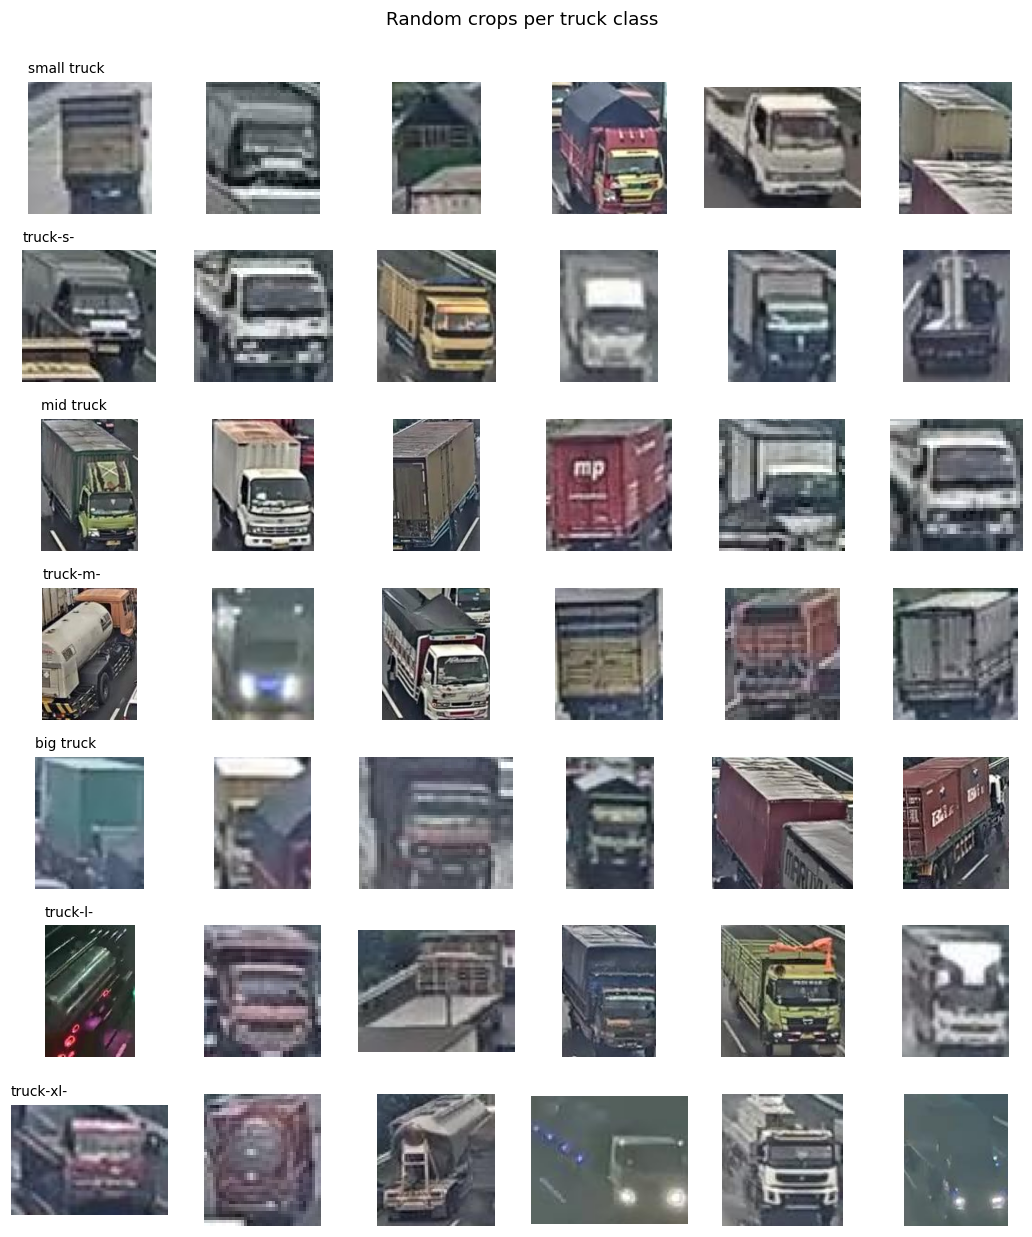

In [6]:
rng = np.random.default_rng(0)
show = ["small truck", "truck-s-", "mid truck", "truck-m-", "big truck", "truck-l-", "truck-xl-"]
k = 6
fig, axes = plt.subplots(len(show), k, figsize=(k * 1.6, len(show) * 1.6))
for r, c in enumerate(show):
    sample = boxes[(boxes.cls == c) & (boxes.area_pct > 0.5)].sample(
        k, random_state=int(rng.integers(1e6))
    )
    for j, (_, b) in enumerate(sample.iterrows()):
        im = cv2.imread(str(ROOT / b.split / "images" / b.image))[:, :, ::-1]
        H, W = im.shape[:2]
        x0, x1 = int((b.cx - b.w / 2) * W), int((b.cx + b.w / 2) * W)
        y0, y1 = int((b.cy - b.h / 2) * H), int((b.cy + b.h / 2) * H)
        axes[r, j].imshow(im[max(y0, 0) : y1, max(x0, 0) : x1])
        axes[r, j].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=9)
plt.suptitle("Random crops per truck class", y=1.0)
plt.tight_layout()

## 3. Do frames from one video appear in several splits?

In [7]:
imgs.pivot_table(index="source", columns="split", values="image", aggfunc="size", fill_value=0)[
    list(SPLITS)
]

split,train,valid,test
source,,,
adit,1025,488,226
aditganteng,453,129,65
malam_04112021,429,127,63
pagi_16112021,471,147,66
siang_15112021_1,256,75,38


All five source videos appear in train, valid and test. Consecutive frames from one video are
near-duplicates, so test scores will be **optimistic** compared with footage from a new camera.
There are only five videos, so a split by video is not practical. We keep the official split
(which keeps results comparable with the published RF100 baselines), state this limitation in
the README, and check generalisation separately on the unseen traffic videos in Phase 3.

## 4. Merged classes: car / bus / truck

In [8]:
merged = boxes.pivot_table(
    index="merged", columns="split", values="image", aggfunc="size", fill_value=0
)[list(SPLITS)].reindex(cfg.merged)
merged["total"] = merged.sum(axis=1)
merged["share"] = (merged.total / merged.total.sum()).round(3)
merged

split,train,valid,test,total,share
merged,,,,,
car,19083,8537,4021,31641,0.613
bus,1134,342,149,1625,0.032
truck,11688,4571,2052,18311,0.355


## Conclusions

- **Merge to car / bus / truck** (mapping in `configs/classes.yaml`). The size sub-classes are
  labelled inconsistently across two naming schemes, overlap in size, and several are too rare
  to evaluate. The smallest merged class (bus) still has 149 test instances, against 0–110 for each bus sub-class.
- **Report both** the official 12-class results (comparable with RF100 baselines: YOLOv5 0.454,
  YOLOv8 0.472 mAP@0.5) and the merged 3-class results (the ones used downstream).
- **Imbalance remains** (cars are ~61% of boxes, buses ~3%), so per-class AP is reported alongside mAP.
- **Leakage caveat:** every source video is in every split; generalisation is tested on unseen
  videos in Phase 3.